In [36]:
import sys
from pathlib import Path

In [37]:
sys.path.insert(0, str(Path.cwd().parent.resolve()))

In [38]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

from scripts.feature_engineering import prepare_features
from scripts.preprocess import create_preprocessing

In [39]:
import importlib
import scripts.feature_engineering as fe

importlib.reload(fe)

prepare_features = fe.prepare_features


In [40]:
train = pd.read_csv("../data/train.csv")

In [41]:
X = prepare_features(train.drop(columns=["damage_grade"]))
y = train["damage_grade"]

In [42]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [43]:
model = Pipeline([
    ("preprocessor", create_preprocessing(X_train)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

In [44]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['Grade 1','Grade 2','Grade 3','Grade 4','Grade 5']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['district_id','vdcmun_id','ward_id',...,'position','plan_configuration', 'superstructure']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped.

In [45]:
predictions = model.predict(X_val)

In [46]:
print(f"Accuracy: {accuracy_score(y_val, predictions)}")
print(f"\nMarco F1 {f1_score(y_val, predictions, average="macro")}")
print("\n",classification_report(y_val, predictions))

Accuracy: 0.5390044332805338

Marco F1 0.5075266495742362

               precision    recall  f1-score   support

     Grade 1       0.53      0.74      0.62     11034
     Grade 2       0.32      0.38      0.35     12216
     Grade 3       0.39      0.38      0.39     19098
     Grade 4       0.49      0.48      0.48     25738
     Grade 5       0.77      0.65      0.70     38607

    accuracy                           0.54    106693
   macro avg       0.50      0.53      0.51    106693
weighted avg       0.56      0.54      0.54    106693



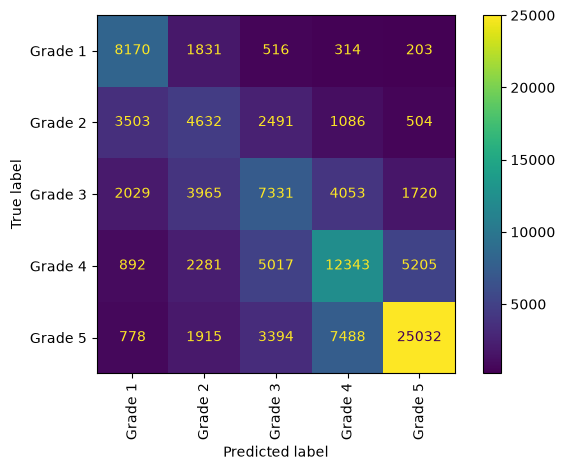

In [47]:
ConfusionMatrixDisplay.from_predictions(y_val, predictions, xticks_rotation="vertical")

plt.tight_layout()
plt.show()